Words: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog', 'the', 'fox', 'is', 'quick', 'and', 'the', 'dog', 'is', 'lazy', 'machine', 'learning', 'is', 'a', 'part', 'of', 'artificial', 'intelligence', 'deep', 'learning', 'is', 'a', 'part', 'of', 'machine', 'learning', 'artificial', 'intelligence', 'is', 'changing', 'the', 'world']
Vocabulary: ['a', 'and', 'artificial', 'brown', 'changing', 'deep', 'dog', 'fox', 'intelligence', 'is', 'jumps', 'lazy', 'learning', 'machine', 'of', 'over', 'part', 'quick', 'the', 'world']
Vocabulary Size: 20
Context Words: [['the', 'quick', 'fox', 'jumps'], ['quick', 'brown', 'jumps', 'over'], ['brown', 'fox', 'over', 'the'], ['fox', 'jumps', 'the', 'lazy'], ['jumps', 'over', 'lazy', 'dog']]
Target Words: ['brown', 'fox', 'jumps', 'over', 'the']
Total Training Examples: 36
Input Shape: (36, 20)
Output Shape: (36, 20)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 50)             │         1,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 20)             │         1,020 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,070 (8.09 KB)

 Trainable params: 2,070 (8.09 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.0278 - loss: 3.0042     
Epoch 2/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0556 - loss: 2.9951    
Epoch 3/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1389 - loss: 2.9874
Epoch 4/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1389 - loss: 2.9806
Epoch 5/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1111 - loss: 2.9738
Epoch 6/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1111 - loss: 2.9668
Epoch 7/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1111 - loss: 2.9604
Epoch 8/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0833 - loss: 2.9538
Epoch 9/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0833 - loss: 2.9470
Epoch 10/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1111 - loss: 2.9408
Epoch 11/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1111 - loss: 2.9341
Epoch 12/300
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.

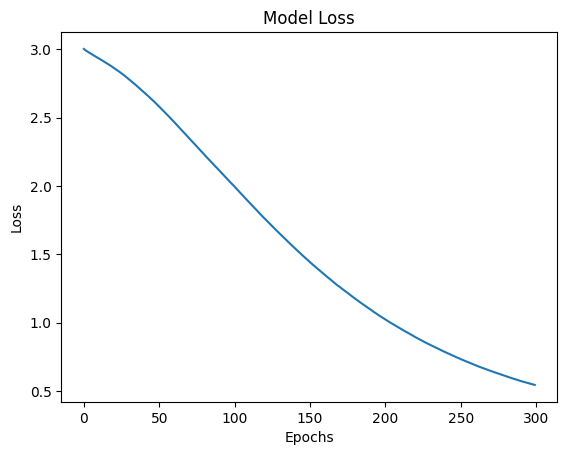

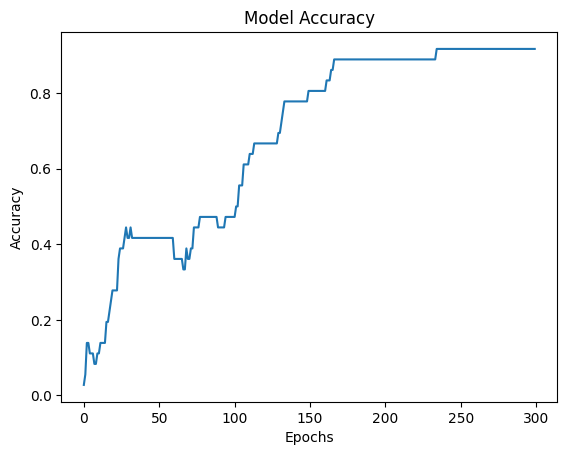

Context Words: ['fox', 'and', 'the', 'is']
Predicted Word: dog


In [5]:

# CBOW (Continuous Bag of Words)

# Step 1: Import Libraries

import numpy as np
import string
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical


# Step 2: Sample Text

text = """
The quick brown fox jumps over the lazy dog.
The fox is quick and the dog is lazy.
Machine learning is a part of artificial intelligence.
Deep learning is a part of machine learning.
Artificial intelligence is changing the world.
"""


# Step 3: Preprocessing

text = text.lower()

words = text.split()

words = [word.strip(string.punctuation) for word in words]

print("Words:", words)


# Step 4: Create Vocabulary

vocab = sorted(set(words))

vocab_size = len(vocab)

word_to_index = {}

for i, word in enumerate(vocab):
    word_to_index[word] = i

index_to_word = {}

for word, index in word_to_index.items():
    index_to_word[index] = word

print("Vocabulary:", vocab)
print("Vocabulary Size:", vocab_size)


# Step 5: Create Context Window and Target Words

window_size = 2

X = []
y = []

for i in range(window_size, len(words) - window_size):

    context_words = []

    for j in range(i - window_size, i + window_size + 1):

        if j != i:
            context_words.append(words[j])

    target_word = words[i]

    X.append(context_words)
    y.append(target_word)

print("Context Words:", X[:5])
print("Target Words:", y[:5])
print("Total Training Examples:", len(X))


# Step 6: Convert Context Words into Numerical Vectors

X_new = []

for context in X:

    vector = np.zeros(vocab_size)

    for word in context:

        index = word_to_index[word]

        vector[index] += 1

    vector = vector / len(context)

    X_new.append(vector)

X = np.array(X_new)


# Step 7: Convert Target Words into One-Hot Encoding

y_new = []

for word in y:

    index = word_to_index[word]

    y_new.append(index)

y = np.array(y_new)

y = to_categorical(y, num_classes=vocab_size)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)


# Step 8: Build CBOW Model

model = Sequential()

model.add(Dense(50, input_shape=(vocab_size,), activation='relu'))

model.add(Dense(vocab_size, activation='softmax'))

model.summary()


# Step 9: Compile the Model

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# Step 10: Train the Model

history = model.fit(
    X,
    y,
    epochs=300,
    batch_size=16
)


# Step 11: Plot Loss

plt.plot(history.history['loss'])

plt.title('Model Loss')

plt.xlabel('Epochs')

plt.ylabel('Loss')

plt.show()


# Step 12: Plot Accuracy

plt.plot(history.history['accuracy'])

plt.title('Model Accuracy')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.show()


# Step 13: Predict the Missing Word

def predict_word(context_words):

    vector = np.zeros(vocab_size)

    valid_words = []

    for word in context_words:

        if word in word_to_index:

            index = word_to_index[word]

            vector[index] += 1

            valid_words.append(word)

    if len(valid_words) == 0:
        return "No valid context words"

    vector = vector / len(valid_words)

    prediction = model.predict(
        np.array([vector]),
        verbose=0
    )

    index = np.argmax(prediction)

    return index_to_word[index]


# Step 14: Test Prediction

context = ["fox", "and", "the", "is"]

print("Context Words:", context)

print("Predicted Word:", predict_word(context))
